In [15]:
import os
import glob

print("Notebook location:")
print(os.getcwd())

print("\nExcel files found:")
print(glob.glob("../data/raw/**/*.xlsx", recursive=True))

Notebook location:
c:\Users\DELL\Downloads\Demand_Prediction-main\Demand_Prediction-main\notebooks

Excel files found:
['../data/raw\\online+retail\\Online Retail.xlsx']


In [18]:
import pandas as pd

file_path = "../data/raw\\online+retail\\Online Retail.xlsx"

retail_df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Shape:", retail_df.shape)

retail_df.head()

Dataset loaded successfully!
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [19]:
print("Dataset shape:", retail_df.shape)

print("\nColumn names:")
print(retail_df.columns.tolist())

print("\nMissing values:")
print(retail_df.isnull().sum())

print("\nData types:")
print(retail_df.dtypes)

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


In [20]:
print("Dataset shape:", retail_df.shape)

print("\nColumn names:")
print(retail_df.columns.tolist())

print("\nMissing values:")
print(retail_df.isnull().sum())

print("\nData types:")
print(retail_df.dtypes)

Dataset shape: (541909, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object


In [21]:
# Clean the retail transaction data

# Remove cancelled transactions
retail_df = retail_df[~retail_df["InvoiceNo"].astype(str).str.startswith("C")]

# Remove invalid quantities
retail_df = retail_df[retail_df["Quantity"] > 0]

# Convert InvoiceDate to datetime
retail_df["InvoiceDate"] = pd.to_datetime(retail_df["InvoiceDate"])

# Create daily demand by summing quantities
demand_df = (
    retail_df
    .groupby(retail_df["InvoiceDate"].dt.date)["Quantity"]
    .sum()
    .reset_index()
)

# Rename columns
demand_df.columns = ["Date", "Demand"]

# Convert Date back to datetime
demand_df["Date"] = pd.to_datetime(demand_df["Date"])

# Sort by date
demand_df = demand_df.sort_values("Date").reset_index(drop=True)

print("Data cleaning completed!")
print("Daily demand records:", len(demand_df))
print("\nDaily demand dataset:")
print(demand_df.head())

Data cleaning completed!
Daily demand records: 305

Daily demand dataset:
        Date  Demand
0 2010-12-01   27007
1 2010-12-02   31348
2 2010-12-03   16471
3 2010-12-05   16451
4 2010-12-06   21951


In [22]:
# Split real demand data into training and testing sets

split_index = int(len(demand_df) * 0.8)

train = demand_df.iloc[:split_index].copy()
test = demand_df.iloc[split_index:].copy()

print("Training data:", len(train), "rows")
print("Testing data:", len(test), "rows")
print("Training period:", train["Date"].min(), "to", train["Date"].max())
print("Testing period:", test["Date"].min(), "to", test["Date"].max())

Training data: 244 rows
Testing data: 61 rows
Training period: 2010-12-01 00:00:00 to 2011-09-29 00:00:00
Testing period: 2011-09-30 00:00:00 to 2011-12-09 00:00:00


ValueError: x and y must have same first dimension, but have shapes (61,) and (147,)

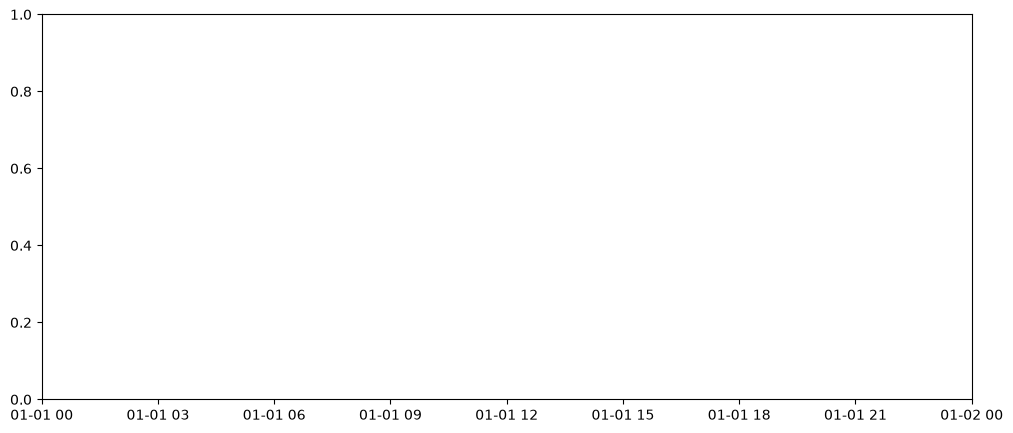

In [23]:
plt.figure(figsize=(12, 5))

plt.plot(test["Date"], y_test.values, label="Actual Demand")
plt.plot(test["Date"], predictions, label="Predicted Demand")

plt.title("Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [24]:
print("Real dataset shape:", retail_df.shape)
print("\nColumns:")
print(retail_df.columns.tolist())

print("\nFirst 5 rows:")
display(retail_df.head())

Real dataset shape: (531285, 8)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [25]:
# Prepare real sales data for demand forecasting

retail_df["InvoiceDate"] = pd.to_datetime(retail_df["InvoiceDate"])

# Keep only valid sales quantities
sales_df = retail_df[retail_df["Quantity"] > 0].copy()

# Convert transaction data into daily demand
daily_demand = (
    sales_df.groupby(sales_df["InvoiceDate"].dt.date)["Quantity"]
    .sum()
    .reset_index()
)

daily_demand.columns = ["Date", "Demand"]
daily_demand["Date"] = pd.to_datetime(daily_demand["Date"])

daily_demand = daily_demand.sort_values("Date").reset_index(drop=True)

print("Daily demand dataset created successfully!")
print("Rows:", len(daily_demand))
print("Date range:", daily_demand["Date"].min(), "to", daily_demand["Date"].max())

daily_demand.head()

Daily demand dataset created successfully!
Rows: 305
Date range: 2010-12-01 00:00:00 to 2011-12-09 00:00:00


,Date,Demand
0,2010-12-01,27007
1,2010-12-02,31348
2,2010-12-03,16471
3,2010-12-05,16451
4,2010-12-06,21951


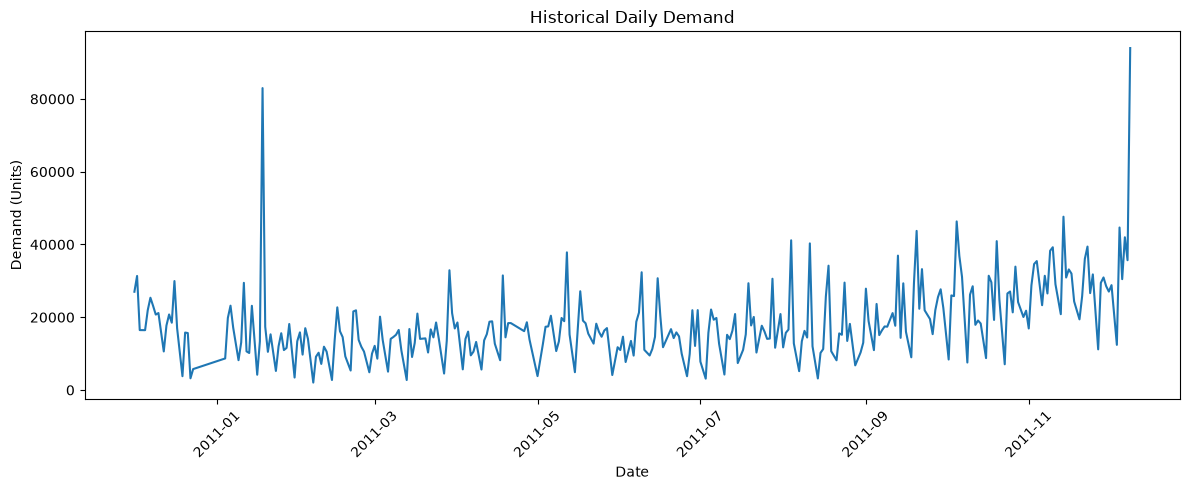

In [26]:
plt.figure(figsize=(12, 5))
plt.plot(daily_demand["Date"], daily_demand["Demand"])
plt.title("Historical Daily Demand")
plt.xlabel("Date")
plt.ylabel("Demand (Units)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
# Train-test split

split_index = int(len(daily_demand) * 0.8)

train = daily_demand.iloc[:split_index].copy()
test = daily_demand.iloc[split_index:].copy()

print("Training data:", len(train), "rows")
print("Testing data:", len(test), "rows")
print("Training period:", train["Date"].min(), "to", train["Date"].max())
print("Testing period:", test["Date"].min(), "to", test["Date"].max())

Training data: 244 rows
Testing data: 61 rows
Training period: 2010-12-01 00:00:00 to 2011-09-29 00:00:00
Testing period: 2011-09-30 00:00:00 to 2011-12-09 00:00:00


In [28]:
# Feature engineering

daily_demand["Day"] = daily_demand["Date"].dt.day
daily_demand["Month"] = daily_demand["Date"].dt.month
daily_demand["DayOfWeek"] = daily_demand["Date"].dt.dayofweek
daily_demand["Year"] = daily_demand["Date"].dt.year

features = ["Day", "Month", "DayOfWeek", "Year"]

X = daily_demand[features]
y = daily_demand["Demand"]

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Forecasting features created successfully!")
print("Features:", features)

Forecasting features created successfully!
Features: ['Day', 'Month', 'DayOfWeek', 'Year']


In [29]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Random Forest model trained successfully!")
print("Predictions generated:", len(predictions))

Random Forest model trained successfully!
Predictions generated: 61


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Model Evaluation Results")
print("------------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

Model Evaluation Results
------------------------
MAE : 10109.01
RMSE: 14648.08


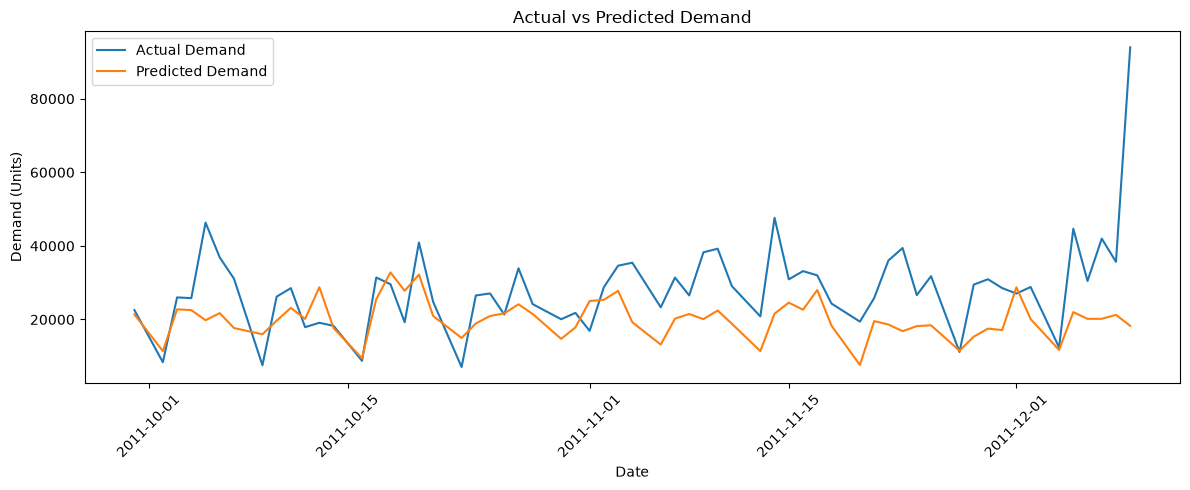

In [31]:
plt.figure(figsize=(12, 5))

plt.plot(test["Date"], y_test.values, label="Actual Demand")
plt.plot(test["Date"], predictions, label="Predicted Demand")

plt.title("Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Demand (Units)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
# Basic Inventory Planning

average_daily_demand = predictions.mean()

demand_variability = np.std(y_test.values - predictions)

lead_time_days = 7
service_factor = 1.65

safety_stock = service_factor * demand_variability

reorder_point = (
    average_daily_demand * lead_time_days
) + safety_stock

print("Basic Inventory Planning")
print("------------------------")
print("Average predicted daily demand:", round(average_daily_demand, 2))
print("Estimated safety stock:", round(safety_stock, 2))
print("Recommended reorder point:", round(reorder_point, 2))

Basic Inventory Planning
------------------------
Average predicted daily demand: 20157.34
Estimated safety stock: 19876.46
Recommended reorder point: 160977.81


In [3]:
# Create a sample historical demand dataset

import pandas as pd
import numpy as np

np.random.seed(42)

dates = pd.date_range(start="2024-01-01", end="2025-12-31", freq="D")

# Trend + weekly seasonality + random variation
trend = np.linspace(100, 150, len(dates))
weekly_pattern = 15 * np.sin(2 * np.pi * np.arange(len(dates)) / 7)
noise = np.random.normal(0, 8, len(dates))

demand = trend + weekly_pattern + noise
demand = np.maximum(demand, 0).round().astype(int)

df = pd.DataFrame({
    "Date": dates,
    "Demand": demand
})

print("Dataset created successfully!")
print("Rows:", len(df))
df.head()

Dataset created successfully!
Rows: 731


,Date,Demand
0,2024-01-01,104
1,2024-01-02,111
2,2024-01-03,120
3,2024-01-04,119
4,2024-01-05,92


In [4]:
# Check the dataset
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nData types:")
print(df.dtypes)

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

# Sort by date
df = df.sort_values("Date").reset_index(drop=True)

print("\nPreprocessing completed successfully!")
print(df.head())

Dataset shape: (731, 2)

Missing values:
Date      0
Demand    0
dtype: int64

Data types:
Date      datetime64[us]
Demand             int64
dtype: object

Preprocessing completed successfully!
        Date  Demand
0 2024-01-01     104
1 2024-01-02     111
2 2024-01-03     120
3 2024-01-04     119
4 2024-01-05      92


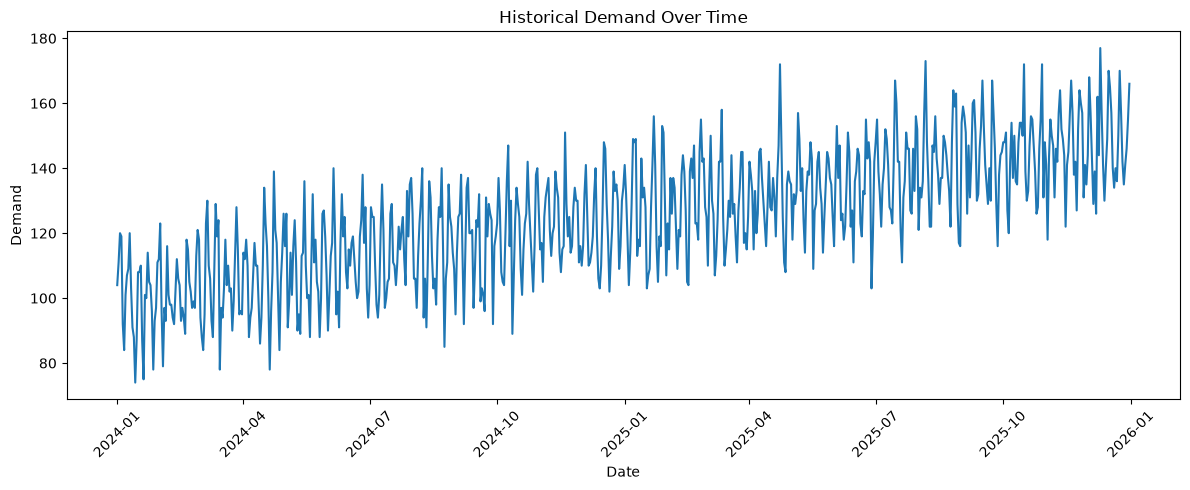

In [5]:
# Plot historical demand over time

plt.figure(figsize=(12, 5))

plt.plot(df["Date"], df["Demand"])

plt.title("Historical Demand Over Time")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [6]:
# Split data into training and testing sets

split_index = int(len(df) * 0.8)

train = df.iloc[:split_index].copy()
test = df.iloc[split_index:].copy()

print("Training data:", len(train), "rows")
print("Testing data:", len(test), "rows")
print("Training period:", train["Date"].min(), "to", train["Date"].max())
print("Testing period:", test["Date"].min(), "to", test["Date"].max())

Training data: 584 rows
Testing data: 147 rows
Training period: 2024-01-01 00:00:00 to 2025-08-06 00:00:00
Testing period: 2025-08-07 00:00:00 to 2025-12-31 00:00:00


In [7]:
# Create time-based features for forecasting

df["Day"] = df["Date"].dt.day
df["Month"] = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.dayofweek
df["Year"] = df["Date"].dt.year

features = ["Day", "Month", "DayOfWeek", "Year"]

X = df[features]
y = df["Demand"]

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Forecasting features created successfully!")
print("Features:", features)


Forecasting features created successfully!
Features: ['Day', 'Month', 'DayOfWeek', 'Year']


In [9]:
from sklearn.ensemble import RandomForestRegressor

# Create the Random Forest model
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
model.fit(X_train, y_train)

# Generate predictions
predictions = model.predict(X_test)

print("Random Forest model trained successfully!")
print("Predictions generated:", len(predictions))

Random Forest model trained successfully!
Predictions generated: 147


In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Model Evaluation Results")
print("------------------------")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

Model Evaluation Results
------------------------
MAE : 8.62
RMSE: 10.81


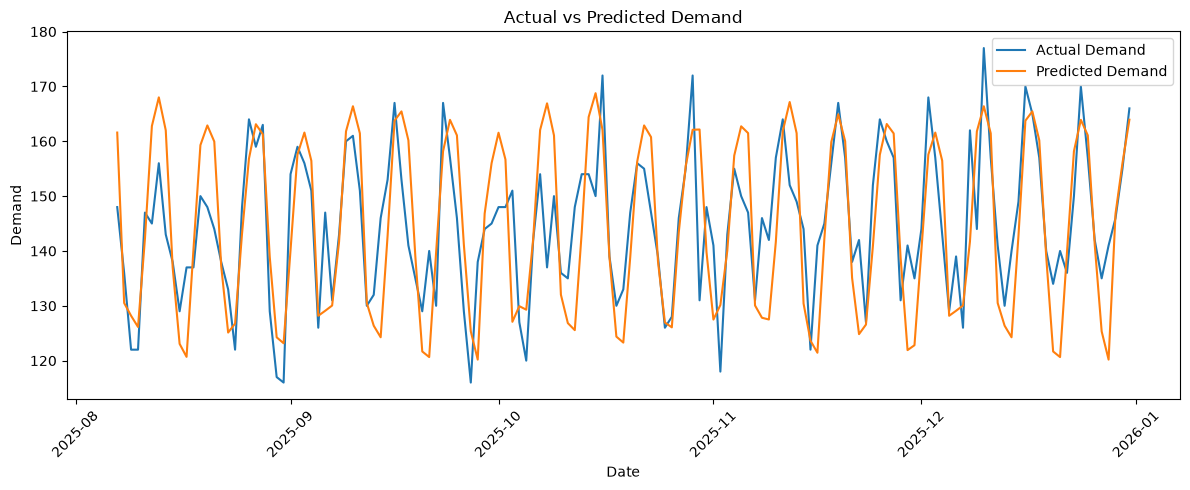

In [11]:
# Compare actual demand with predicted demand

plt.figure(figsize=(12, 5))

plt.plot(test["Date"], y_test.values, label="Actual Demand")
plt.plot(test["Date"], predictions, label="Predicted Demand")

plt.title("Actual vs Predicted Demand")
plt.xlabel("Date")
plt.ylabel("Demand")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

In [12]:
# Basic inventory / replenishment recommendation

average_daily_demand = predictions.mean()
demand_variability = np.std(y_test.values - predictions)

lead_time_days = 7
service_factor = 1.65

safety_stock = service_factor * demand_variability
reorder_point = (average_daily_demand * lead_time_days) + safety_stock

print("Basic Inventory Planning")
print("------------------------")
print("Average predicted daily demand:", round(average_daily_demand, 2))
print("Estimated safety stock:", round(safety_stock, 2))
print("Recommended reorder point:", round(reorder_point, 2))

Basic Inventory Planning
------------------------
Average predicted daily demand: 144.51
Estimated safety stock: 17.83
Recommended reorder point: 1029.4


In [13]:
# Final project results summary

print("======================================")
print("AI-POWERED DEMAND FORECASTING SYSTEM")
print("======================================")

print("\nDataset:")
print("Historical records:", len(df))

print("\nModel:")
print("Random Forest Regressor")

print("\nEvaluation:")
print("MAE :", round(mae, 2))
print("RMSE:", round(rmse, 2))

print("\nInventory Planning:")
print("Average predicted demand:", round(average_daily_demand, 2))
print("Safety stock:", round(safety_stock, 2))
print("Reorder point:", round(reorder_point, 2))

print("\nForecasting pipeline completed successfully.")

AI-POWERED DEMAND FORECASTING SYSTEM

Dataset:
Historical records: 731

Model:
Random Forest Regressor

Evaluation:
MAE : 8.62
RMSE: 10.81

Inventory Planning:
Average predicted demand: 144.51
Safety stock: 17.83
Reorder point: 1029.4

Forecasting pipeline completed successfully.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully")

Matplotlib is building the font cache; this may take a moment.


Libraries loaded successfully
